In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path().resolve().parents[0]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))
    
    

from src.config import PROCESSED_DATA_DIR
from src.utils.plots import save_figure, style_plot, create_figure, add_bar_labels, add_source, YOUTUBE_RED, save_table, interpret_eta_squared, DARK_RED
import pandas as pd

Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q2/source-distribution.png


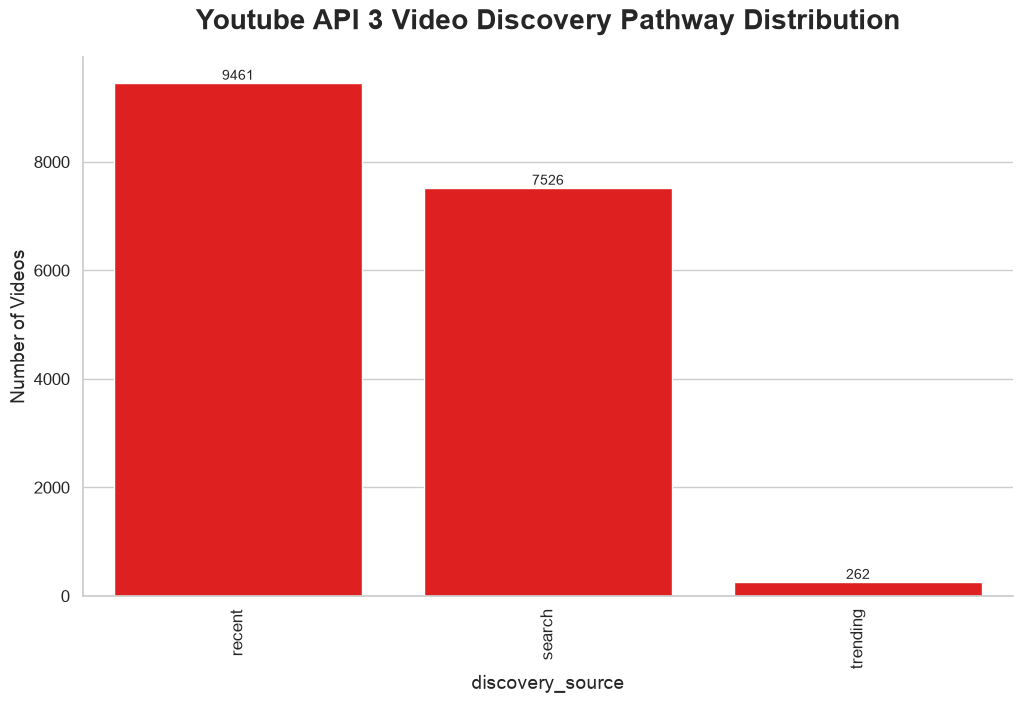

,video_id,title,description,published_at,category_id,tags,duration,channel_id,channel_title,views,...,hour,day_of_week,duration_seconds,duration_minutes,is_short,duration_group,is_viral,tag_count,has_tags,category_name
0,ELkyDvO-j6Q,treat u right,Provided to YouTube by EMPIRE Distribution\n\n...,2026-07-02 22:11:35+00:00,10,"['FOLA', 'Ayra Starr', 'treat u right']",PT2M58S,UC4mHpkf_26sEWN8M5PMpV_w,FOLA - Topic,120661,...,22,3,178,2.97,0,1-5 mins,0,3,True,Music
1,hMlHf-YXVUM,ALAKADA GEN Z 3 (Official Trailer) | Latest Ni...,ALAKADA GEN Z 3 Official Trailer is here! 🎬😂 \...,2026-07-05 17:00:39+00:00,24,"['Alakada Gen Z 3', 'Alakada Gen Z 3 trailer',...",PT2M33S,UCoSnFVOBlcdgjSUETGd65kA,Toyin Abraham TV,69067,...,17,6,153,2.55,0,1-5 mins,0,23,True,Entertainment
2,BaO6Dnxquv8,🔴 GTA 5 LIVE – DON’T BLINK! SECRET MOD ACTIVAT...,🔴 GTA 5 LIVE – DON’T BLINK! SECRET MOD ACTIVAT...,2026-07-05 20:06:24+00:00,20,"['gta 5 live', 'gta v live stream', 'gta 5 gam...",PT31M8S,UC9OTne2HnCn_kkyx8NodI-g,Pixel Hunters,14163447,...,20,6,1868,31.13,0,15-60 mins,1,25,True,Gaming
3,KkDHSWq7XGw,Jorja Smith - Alive feat. Wizkid,Jorja Smith - Alive feat. Wizkid - Out now: ht...,2026-07-02 16:00:27+00:00,10,"['jorja smith', 'alive', 'wizkid', 'what are t...",PT3M31S,UCHA6dVPvxRdLQ5Uu-uX3MLw,Jorja Smith,952264,...,16,3,211,3.52,0,1-5 mins,0,5,True,Music
4,DVHPZ36Sav8,IYE Latest Yoruba Movie 2026 l Official Traile...,Some homes don’t let you leave…\nAnd if you do...,2026-06-29 17:00:24+00:00,22,[],PT1M28S,UCi00_82Wh1q_rm2Yz8m7GIA,THE DAMILOLA ONI TV,72623,...,17,0,88,1.47,0,1-5 mins,0,0,False,People & Blogs


<Figure size 640x480 with 0 Axes>

In [11]:
df = pd.read_csv(PROCESSED_DATA_DIR / "youtube_clean.csv")

source_count = (
    df["discovery_source"].value_counts()
    .sort_values(ascending=False)
    )

# video distribution by source
fig, ax = create_figure()
sns.barplot(
    x=source_count.index,
    y=source_count.values,
    ax=ax,
    color=YOUTUBE_RED
)
ax.tick_params(axis="x", rotation=90)

style_plot(ax=ax, xlabel='discovery_source', ylabel='Number of Videos', title="Youtube API 3 Video Discovery Pathway Distribution")
add_bar_labels(ax)
save_figure(fig=fig,  filename='q2/source-distribution.png')
plt.show()
plt.clf()


df.head()

/var/folders/w8/kmbm7vc17vb80lb9kj5f78mw0000gn/T/ipykernel_1899/522190869.py:12: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  sns.barplot(


Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q2/category-dominance.png


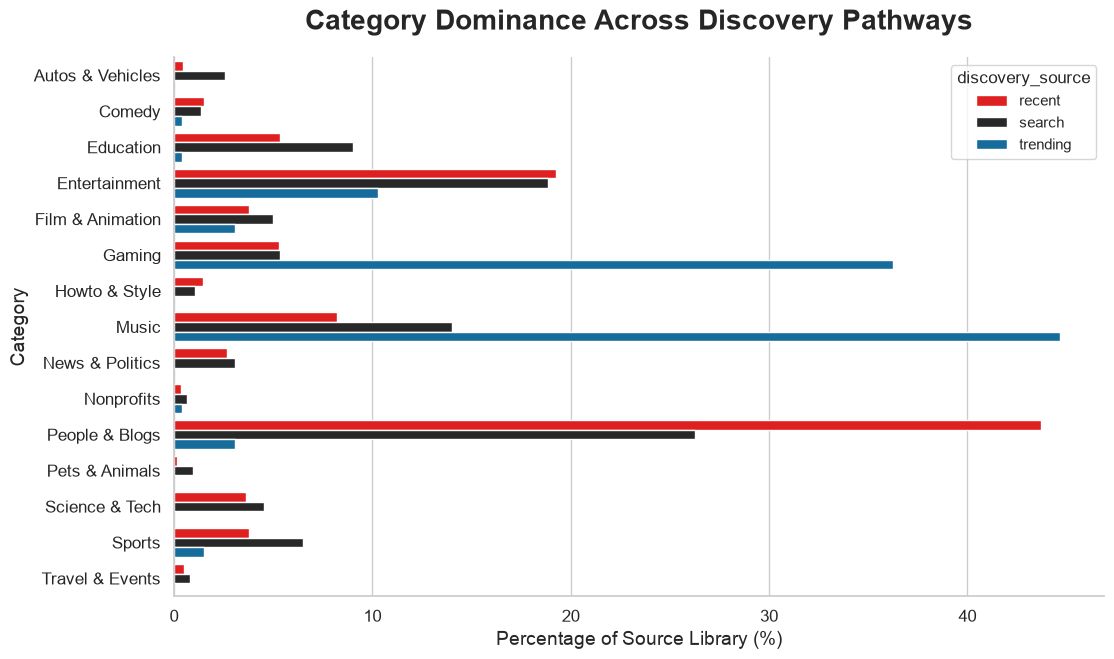

<Figure size 640x480 with 0 Axes>

In [10]:
# which count category dominates each discovery channel


source_counts = df.groupby(['discovery_source', 'category_name']).size().reset_index(name='count')
source_totals = df.groupby('discovery_source').size().reset_index(name='total')
norm_df = pd.merge(source_counts, source_totals, on='discovery_source')
norm_df['percentage'] = (norm_df['count'] / norm_df['total']) * 100

# Plotting 
fig, ax = create_figure()

sns.barplot(
    data=norm_df,
    y='category_name',
    x='percentage',
    hue='discovery_source',
    ax=ax,
    palette=['#FF0000', '#282828', '#0073B1', '#00A86B'] # Unified theme colors
)

style_plot(
    ax=ax, 
    xlabel='Percentage of Source Library (%)', 
    ylabel='Category', 
    title='Category Dominance Across Discovery Pathways'
)

save_figure(fig=fig, filename='q2/category-dominance.png')
plt.show()
plt.clf()




Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q2/disproportionate-amplification-scatter.png


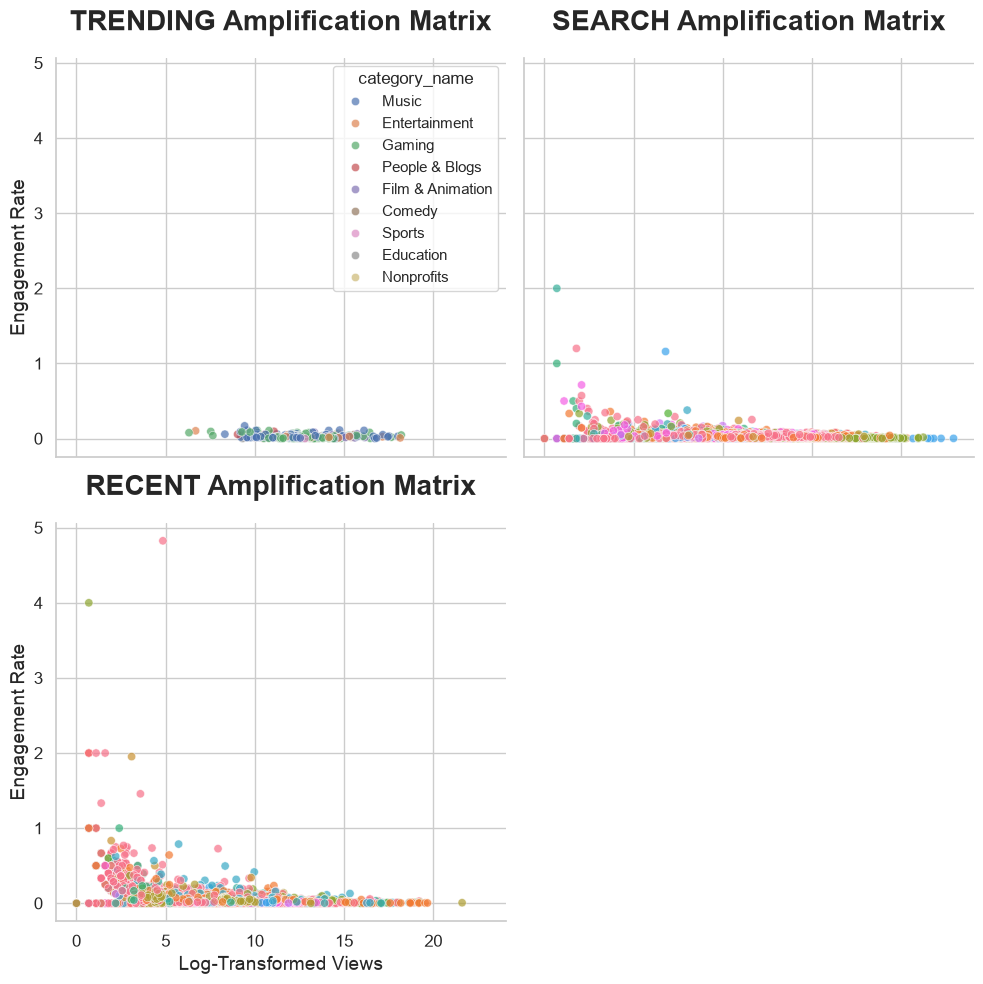

<Figure size 640x480 with 0 Axes>

In [ ]:
# Visualizing Disproportionate Amplification: Engagement vs. Scale
fig, axes = plt.subplots(2, 2, figsize=(10, 10), sharey=True, sharex=True)
axes_flat = axes.flatten()

# all distinct pathways
unique_sources = df['discovery_sources'].unique()

for i, source in enumerate(unique_sources):
    ax = axes_flat[i]
    source_data = df[df['discovery_source'] == source]
    
    sns.scatterplot(
        data=source_data,
        x='log_views',             
        y='engagement_rate',
        hue='category_name',
        ax=ax,
        alpha=0.7,
        legend=True if i == 0 else False 
    )
    
   
    style_plot(
        ax=ax, 
        xlabel='Log-Transformed Views', 
        ylabel='Engagement Rate' if i in [0, 2] else '', 
        title=f"{source.upper()} Amplification Matrix"
    )

# hide unused axis
axes_flat[3].set_visible(False)



plt.tight_layout()
save_figure(fig=fig, filename='q2/disproportionate-amplification-scatter.png')
plt.show()
plt.clf()

Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q2/pathway-visibility-bars.png


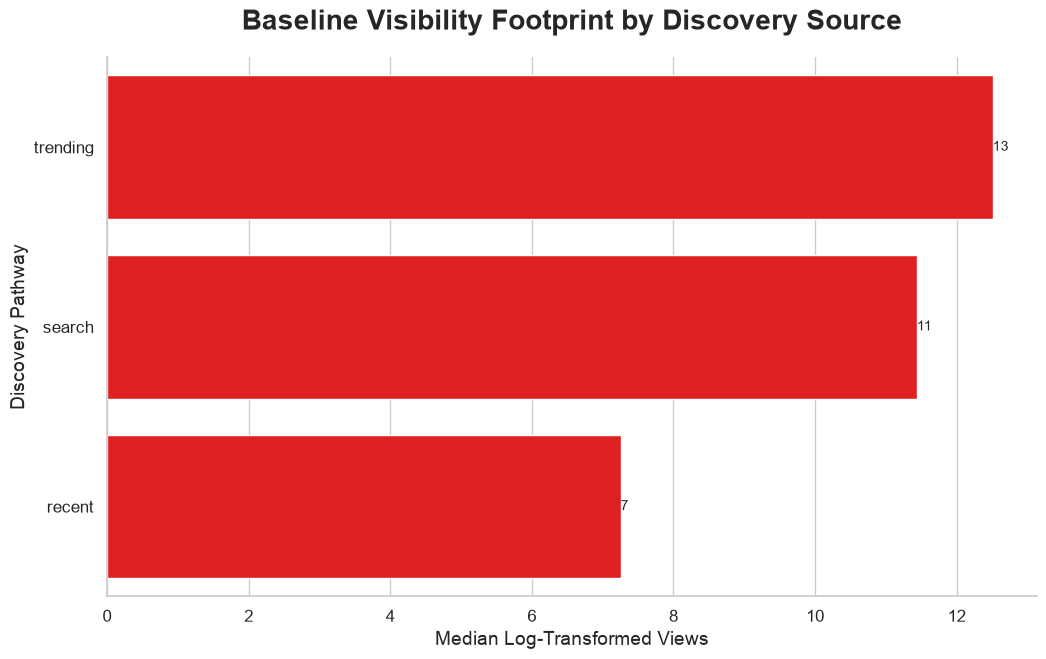

<Figure size 640x480 with 0 Axes>

In [13]:
# median view per pathway
pathway_visibility = df.groupby('discovery_source')['log_views'].median().sort_values(ascending=False).reset_index()

fig, ax = create_figure()

sns.barplot(
data=pathway_visibility,
x='log_views',
y='discovery_source',
ax=ax,
color=YOUTUBE_RED
)

style_plot(
ax=ax,
xlabel='Median Log-Transformed Views',
ylabel='Discovery Pathway',
title='Baseline Visibility Footprint by Discovery Source'
)

add_bar_labels(ax)

save_figure(fig=fig, filename='q2/pathway-visibility-bars.png')
plt.show()
plt.clf()

In [14]:
#cross tabs
rq2_matrix = pd.crosstab(
    df['discovery_source'], 
    df['category_name'], 
    normalize='index'
) * 100

print(rq2_matrix.round(2).to_string())

category_name     Autos & Vehicles  Comedy  Education  Entertainment  Film & Animation  Gaming  Howto & Style  Music  News & Politics  Nonprofits  People & Blogs  Pets & Animals  Science & Tech  Sports  Travel & Events
discovery_source                                                                                                                                                                                                          
recent                        0.43    1.50       5.34          19.27              3.77    5.30           1.44   8.20             2.65        0.37           43.70            0.15            3.63    3.77             0.49
search                        2.55    1.34       9.02          18.85              5.00    5.35           1.06  14.03             3.07        0.66           26.24            0.97            4.54    6.48             0.81
trending                      0.00    0.38       0.38          10.31              3.05   36.26           0.00  44.66        

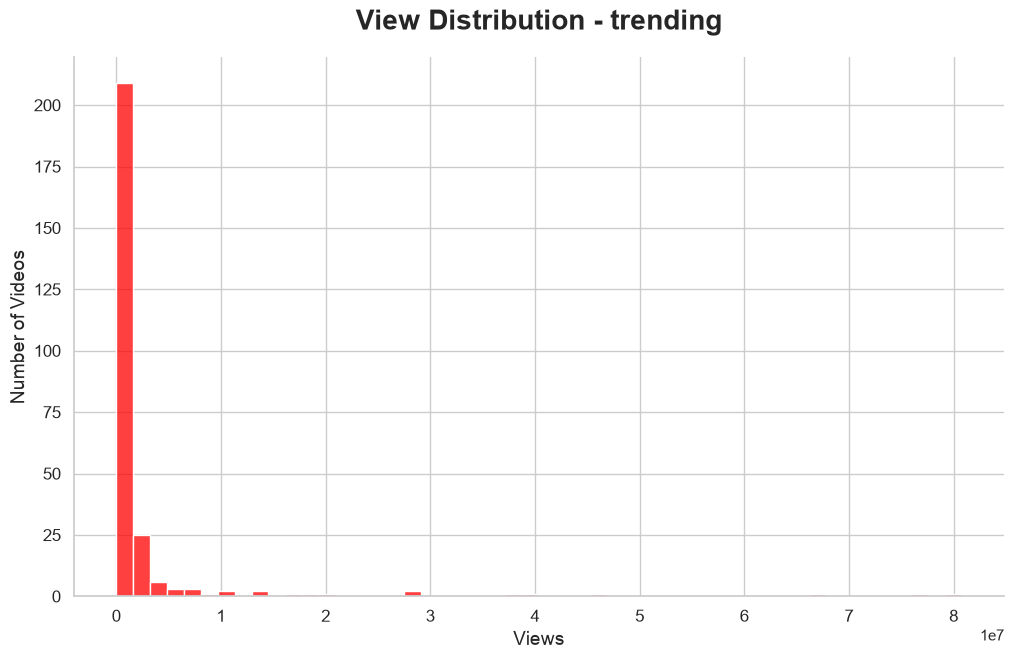

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [ ]:
# 
sources = df["discovery_source"].unique()
fig, axes = create_figure(nrows=1, ncols=3, sharey=False)

for source in sources:

    subset = df[df["discovery_source"] == source]

    sns.histplot(
        subset['views'],
        bins=50,
        ax=ax,
        color=YOUTUBE_RED
    )
    style_plot(
        ax=ax,
        xlabel='Views',
        ylabel='Number of Videos',
        title=f'View Distribution - {source}'
    )




    plt.show()
    plt.clf()